# Will a Netflix Title Stay in the Top 10?

![netflix_header](netflix_header.png)

Every week, Netflix publishes its 10 most watched films and TV shows, for the whole world and for each country. In this notebook I use these lists to answer a simple question: **after one week in the global top 10, can we tell if a title will still be there a month later?**

The project started as a free DataCamp workspace, with a few guiding questions and a scenario about content duration. I use the guiding questions along the way in the exploration. I did not follow the duration scenario: runtime only exists for the last 11 weeks of the data, which is too short to study it. The rest is my own end-to-end project.

**A note on AI use:** The code, the analysis, and the conclusions are my own work. I used AI (Claude) as a writing aid, to help me phrase my findings clearly and to tidy the notebook's formatting and comments.

## Context

Netflix ranks titles in four lists every week: English films, non-English films, English TV and non-English TV. The data covers June 2021 to August 2023 and comes in two files ([source: Netflix](https://www.netflix.com/tudum/top10/united-states?week=2023-08-27)):

| File | Content |
| --- | --- |
| `data/netflix_top10.csv` | the **global** lists: `week`, `category`, `weekly_rank`, `show_title`, `season_title`, `weekly_hours_viewed`, `runtime`, `weekly_views`, `cumulative_weeks_in_top_10`, `is_staggered_launch`, `episode_launch_details` |
| `data/netflix_top10_country.csv` | the same lists **for each country**: `country_name`, `country_iso2`, `week`, `category`, `weekly_rank`, `show_title`, `season_title`, `cumulative_weeks_in_top_10` |

Imagine a content team that has to decide how much marketing to put behind a new title. A title that stays in the top 10 for a long time is worth a bigger push. But the team has to decide early, after the first week, without knowing how the run will end.

## Goal

I want to predict, from a title's **first week only**, whether it will stay in the global top 10 for **4 weeks or more**. The notebook has two parts.

**Part 1, exploratory data analysis.** I get to know the data before modeling:

- **look at how long titles usually stay**, to check that 4 weeks is a sensible line between a normal run and a long one
- **see how films and TV share the top 10**, which answers one of the guiding questions of the workspace
- **group the countries that watch the same things.** By comparing the top 10 lists of the 94 countries, I find groups of countries with similar tastes, which I call **taste groups** (for example Latin America or South Asia). This answers another guiding question, about regional tastes, and stands on its own: the models do not use it.

**Part 2, prediction with machine learning.**

- **describe each title by what is known after week 1**: its global rank, its hours viewed, the number of countries where it is in the top 10 and its mean rank across the countries
- **train models on the 2021–2022 titles and test them on the 2023 titles.** This is how the team would use it: learn from the past, then predict new titles

## Plan

1. **Setup**: libraries and fixed settings

**Part 1: exploratory data analysis**

2. **Load and check the data**: what the files contain and what is missing
3. **How long do titles stay?** Typical runs, films against TV, and how Netflix ranks titles
4. **Which countries watch the same things?** Grouping the countries into taste groups

**Part 2: prediction**

5. **Describe each title by its first week**: one row per title, with what is known after week 1 and whether it stayed 4 weeks or more
6. **Predict which titles will stay**: train on 2021–2022, test on 2023
7. **What the predictions rely on**: which first-week signals matter most
8. **Conclusion and advice for the content team**

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, set_link_color_palette
from scipy.spatial.distance import squareform
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

# These variables are used in multiple places, so we define them here to avoid magic numbers in the code
RANDOM_STATE = 42  # used every time there is randomness
TARGET_WEEKS = 4  # a title "stays" if it spends at least 4 weeks in the global top 10
N_TASTE_GROUPS = 11  # number of country taste groups, chosen with the elbow plot in 4.2
ABSENT_RANK = 11  # rank given to a title in a country where it is not in the top 10
CV_FOLDS = 5  # number of folds for cross-validation

BLUE = "#2a78d6"  # main colour of the figures
ORANGE = "#eb6834"  # colour used to highlight
CATEGORY_COLORS = {  # one fixed colour per list
    "Films (English)": "#2a78d6",
    "Films (Non-English)": "#7fb3e8",
    "TV (English)": "#eb6834",
    "TV (Non-English)": "#f5b08f",
}

# Part 1: Exploratory data analysis

Before building any model, I get to know the data: what the files contain, how long titles stay in the top 10, and which countries watch the same things.

## 2. Load and check the data

I start by loading the two files and looking at what they contain: the global lists in `global_top_10` and the country lists in `countries_top_10`. Then I check the dates, the missing values and the columns I can rely on.

In [2]:
global_top_10 = pd.read_csv("data/netflix_top10.csv")
print(global_top_10.shape)
global_top_10.head()

(4520, 11)


,week,category,weekly_rank,show_title,season_title,weekly_hours_viewed,runtime,weekly_views,cumulative_weeks_in_top_10,is_staggered_launch,episode_launch_details
0,2023-08-27,Films (English),1,The Monkey King,NaN,23200000,1.6167,14400000.0,2,False,NaN
1,2023-08-27,Films (English),2,Heart of Stone,NaN,28500000,2.1000,13600000.0,3,False,NaN
2,2023-08-27,Films (English),3,You Are So Not Invited to My Bat Mitzvah,NaN,21300000,1.7333,12300000.0,1,False,NaN
3,2023-08-27,Films (English),4,Street Kings,NaN,10300000,1.8167,5700000.0,2,False,NaN
4,2023-08-27,Films (English),5,The Boss Baby,NaN,9000000,1.6333,5500000.0,10,False,NaN


In [3]:
countries_top_10 = pd.read_csv("data/netflix_top10_country.csv")
print(countries_top_10.shape)
countries_top_10.head()

(210880, 8)


,country_name,country_iso2,week,category,weekly_rank,show_title,season_title,cumulative_weeks_in_top_10
0,Argentina,AR,2023-08-27,Films,1,On the Line,NaN,1
1,Argentina,AR,2023-08-27,Films,2,Half Brothers,NaN,2
2,Argentina,AR,2023-08-27,Films,3,Street Kings,NaN,3
3,Argentina,AR,2023-08-27,Films,4,You Are So Not Invited to My Bat Mitzvah,NaN,1
4,Argentina,AR,2023-08-27,Films,5,Heart of Stone,NaN,3


In [4]:
global_top_10.info()

<class 'pandas.DataFrame'>
RangeIndex: 4520 entries, 0 to 4519
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   week                        4520 non-null   str    
 1   category                    4520 non-null   str    
 2   weekly_rank                 4520 non-null   int64  
 3   show_title                  4520 non-null   str    
 4   season_title                2187 non-null   str    
 5   weekly_hours_viewed         4520 non-null   int64  
 6   runtime                     440 non-null    float64
 7   weekly_views                440 non-null    float64
 8   cumulative_weeks_in_top_10  4520 non-null   int64  
 9   is_staggered_launch         4520 non-null   bool   
 10  episode_launch_details      17 non-null     str    
dtypes: bool(1), float64(2), int64(3), str(5)
memory usage: 613.2 KB


### 2.1 Dates and one key per title

`week` is stored as text, so I convert it to a date in both files.

A TV show can come back with a new season, and each season has its own run in the top 10. So I treat each season as a separate title, and join `show_title` and `season_title` into one `key`. Films have no season, so their missing season becomes an empty text. From now on, a "title" means one film or one season of a show.

In [5]:
global_top_10["week"] = pd.to_datetime(global_top_10["week"])  # convert the text to a date
countries_top_10["week"] = pd.to_datetime(countries_top_10["week"])

global_top_10["key"] = global_top_10["show_title"] + "|" + global_top_10["season_title"].fillna("")  # one key per title and season
countries_top_10["key"] = countries_top_10["show_title"] + "|" + countries_top_10["season_title"].fillna("")

print("First week:", global_top_10["week"].min().date())
print("Last week:", global_top_10["week"].max().date())
print("\nNumber of weeks:", global_top_10["week"].nunique())
print("Unique title-seasons:", global_top_10["key"].nunique())
print("Countries:", countries_top_10["country_name"].nunique())

First week: 2021-07-04
Last week: 2023-08-27

Number of weeks: 113
Unique title-seasons: 1606
Countries: 94


The global file has 4,520 rows: 113 weeks × 4 lists × 10 titles, from 2021-07-04 to 2023-08-27. They cover 1,606 different titles. The country file has 210,880 rows for 94 countries.

### 2.2 Missing values: what to clean and what to leave

A supervised machine learning model cannot use empty cells. So before going further, I am checking which columns have missing values in both files, and decide for each one whether to fill it, leave it out, or keep it as it is.

In [6]:
print("Missing values in the global file:")
print(global_top_10.isna().sum())
print("\nMissing values in the country file:")
print(countries_top_10.isna().sum())
print("\nDuplicated rows:", global_top_10.duplicated().sum(), "in the global file,", countries_top_10.duplicated().sum(), "in the country file")

Missing values in the global file:
week                             0
category                         0
weekly_rank                      0
show_title                       0
season_title                  2333
weekly_hours_viewed              0
runtime                       4080
weekly_views                  4080
cumulative_weeks_in_top_10       0
is_staggered_launch              0
episode_launch_details        4503
key                              0
dtype: int64

Missing values in the country file:
country_name                       0
country_iso2                       0
week                               0
category                           0
weekly_rank                        0
show_title                         0
season_title                  108945
cumulative_weeks_in_top_10         0
key                                0
dtype: int64



Duplicated rows: 0 in the global file, 0 in the country file


In [7]:
with_runtime = global_top_10[global_top_10["runtime"].notna()]  # select the rows where runtime is filled

print("First week with runtime:", with_runtime["week"].min().date())
print("Weeks with runtime:", with_runtime["week"].nunique())
print("Rows with runtime:", len(with_runtime))
print("Titles with runtime:", with_runtime["show_title"].nunique(), "(title-seasons:", with_runtime["key"].nunique(), ")")
print("Share of staggered launches:", round(global_top_10["is_staggered_launch"].mean(), 4))

First week with runtime: 2023-06-18
Weeks with runtime: 11
Rows with runtime: 440
Titles with runtime: 193 (title-seasons: 203 )
Share of staggered launches: 0.0038


What I decide:

- **`season_title` is empty for films**, because a film has no season. This is not an error, so I keep it this way. I already replaced it with an empty text when building the `key` in section 2.1.
  
- **`runtime` and `weekly_views` are empty in almost every row.** The values only start to appear on 2023-06-18, so they cover the last 11 weeks (440 rows). Filling them would mean inventing most of the column, so I will drop them so the models do not use them. I will still keep `weekly_views` for now because I use it in section 3.2, where it shows how Netflix ranks titles.
  
- **`episode_launch_details` is almost always empty, and `is_staggered_launch` is True in only 0.4% of the rows.** They carry almost no information.
  
- **Every other column is complete**, and neither file has duplicated rows, so no other cleaning is needed.

So I can drop `runtime`, `episode_launch_details` and `is_staggered_launch`, because I will not use them anywhere.

In [8]:
global_top_10 = global_top_10.drop(columns=["runtime", "episode_launch_details", "is_staggered_launch"])  # columns I do not use
global_top_10.columns.tolist()

['week',
 'category',
 'weekly_rank',
 'show_title',
 'season_title',
 'weekly_hours_viewed',
 'weekly_views',
 'cumulative_weeks_in_top_10',
 'key']

## 3. How long do titles stay?

Before predicting anything, I need to know what a normal run in the top 10 looks like, to decide what "staying" means. 

Therefore, I wil look at how Netflix builds its ranking and how films and TV share the top 10, since both matter for the model later.

### 3.1 Length of a run

`cumulative_weeks_in_top_10` counts how many weeks a title has spent in the top 10 so far, so its highest value for a title is the full length of its run.

In [9]:
title_runs = global_top_10.groupby("key").agg(
    category=("category", "first"),
    total_weeks=("cumulative_weeks_in_top_10", "max"),  # length of the run, in weeks
)

title_runs["total_weeks"].describe()

count    1606.000000
mean        2.811333
std         2.710293
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max        30.000000
Name: total_weeks, dtype: float64

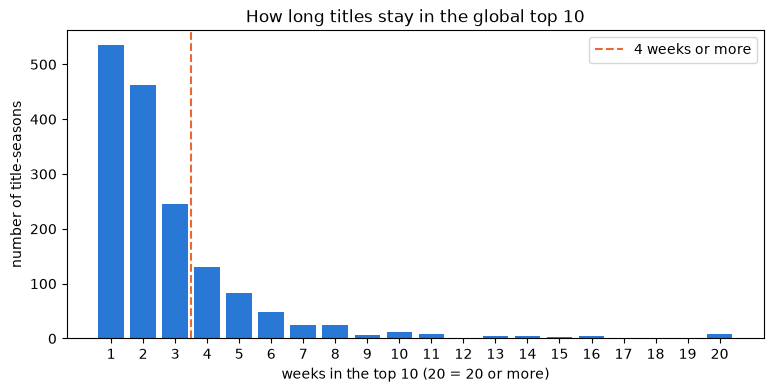

In [10]:
week_counts = title_runs["total_weeks"].clip(upper=20).value_counts().sort_index()  # runs longer than 20 weeks are grouped as if they were 20 weeks long

plt.figure(figsize=(9, 4))
plt.bar(week_counts.index, week_counts.values, color=BLUE)
plt.axvline(TARGET_WEEKS - 0.5, color=ORANGE, linestyle="--", label=f"{TARGET_WEEKS} weeks or more")
plt.title("How long titles stay in the global top 10")
plt.xlabel("weeks in the top 10 (20 = 20 or more)")
plt.ylabel("number of title-seasons")
plt.xticks(range(1, 21))
plt.legend()
plt.show()

Most titles leave quickly: the median run is 2 weeks, three quarters of the titles leave after 3 weeks or less, and only 22.7% of the titles stay 4 weeks or more.

Share of all title-seasons staying 4 weeks or more: 0.227 

category
Films (English)        0.154
Films (Non-English)    0.185
TV (English)           0.297
TV (Non-English)       0.327
Name: total_weeks, dtype: float64


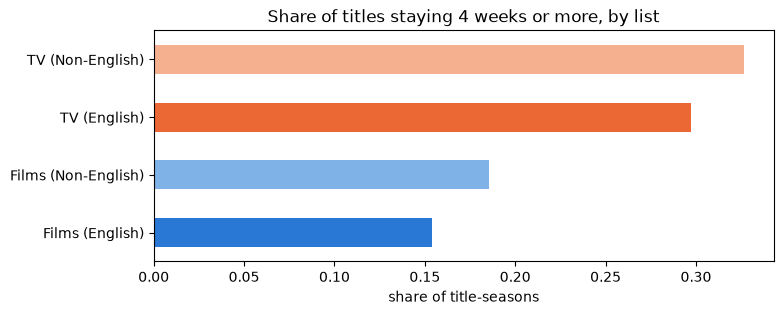

In [11]:
print("Share of all title-seasons staying 4 weeks or more:", round((title_runs["total_weeks"] >= TARGET_WEEKS).mean(), 3),"\n") # percentage of title-seasons that stay in the top 10 for at least 4 weeks, with 3 decimals

share_staying = (title_runs["total_weeks"] >= TARGET_WEEKS).groupby(title_runs["category"]).mean()  # share of titles staying 4+ weeks in each list
print(share_staying.round(3))

share_staying.plot(kind="barh", color=[CATEGORY_COLORS[c] for c in share_staying.index], figsize=(8, 3)) # plot a bar chart with one specific color bar for each category
plt.title(f"Share of titles staying {TARGET_WEEKS} weeks or more, by list")
plt.xlabel("share of title-seasons")
plt.ylabel("")
plt.show()

TV seasons stay longer than films, in both English and other languages: 
- about 30% of English TV andabout 33% of non-English TV stay 4+ weeks
- against 15% of English films and 19% of non-English films.

### 3.2 How does Netflix rank titles?

The data has two ways to measure popularity: hours viewed, and views (hours viewed divided by the runtime, so it gives roughly the number of people who watched the whole title). 

Netflix said in 2023 that it would switch to views. So I decided to check it in the data: for each week and each list, if the rank follows one measure, sorting the 10 titles by that measure gives exactly the ranks 1 to 10.

In [12]:
rank_check = []

for (week, category), week_list in global_top_10.groupby(["week", "category"]):  # one group = one list of 10 titles

    by_hours = week_list.sort_values("weekly_hours_viewed", ascending=False)["weekly_rank"].tolist()  # ranks when sorted by hours

    by_views = week_list.sort_values("weekly_views", ascending=False)["weekly_rank"].tolist()  # ranks when sorted by views
    
    rank_check.append({
        "week": week,
        "category": category,
        "ordered_by_hours": by_hours == list(range(1, 11)),
        "ordered_by_views": week_list["weekly_views"].notna().all() and by_views == list(range(1, 11)),
    })

rank_check = pd.DataFrame(rank_check)
rank_check["period"] = np.where(rank_check["week"] >= "2023-06-18", "from 2023-06-18", "before 2023-06-18")
rank_check.groupby("period")[["ordered_by_hours", "ordered_by_views"]].mean()

,ordered_by_hours,ordered_by_views
period,,
before 2023-06-18,1.000000,0.0
from 2023-06-18,0.022727,1.0


The table shows the share of weekly lists that follow each measure:

- Before 2023-06-18, views do not exist yet, and every list follows the hours.
- From 2023-06-18, every list follows the views.

So **Netflix changed its ranking in June 2023**. This matters because hours favour long content: an 8-hour season collects more hours than a 2-hour film watched by the same number of people. A rank from 2021 and a rank from mid-2023 do not mean exactly the same thing, and I come back to this when I test the models.

### 3.3 Films and TV over time

The first step needs to merge the four lists (Films/TV, English/Non English) into **one weekly top 10**. Views only exist at the very end of the dataset, so I use hours viewed, which exist for the whole period. 

Each week, I keep the 10 titles with the most hours out of the top 40 titles of the 4 lists.

In [13]:
combined_top_10 = ( # combine the global top 10 lists of all weeks into one dataframe, keeping only the 10 most watched titles of each week
    global_top_10
    .sort_values(["week", "weekly_hours_viewed"], ascending=[True, False])  # inside each week, most watched first
    .groupby("week")
    .head(10)  # keep the 10 most watched titles of each week, all lists together
)

last_week = global_top_10["week"].max() # get the last week in the dataset
combined_top_10[combined_top_10["week"] == last_week][["category", "show_title", "season_title", "weekly_hours_viewed"]] # display the top 10 titles of the last week

,category,show_title,season_title,weekly_hours_viewed
20,TV (English),Who is Erin Carter?,Who is Erin Carter?: Limited Series,75400000
30,TV (Non-English),Mask Girl,Mask Girl: Season 1,50800000
31,TV (Non-English),Ragnarok,Ragnarok: Season 3,28800000
1,Films (English),Heart of Stone,NaN,28500000
22,TV (English),Painkiller,Painkiller: Limited Series,27800000
34,TV (Non-English),Baki Hanma,Baki Hanma: Season 2,27700000
0,Films (English),The Monkey King,NaN,23200000
24,TV (English),The Ultimatum: Marry or Move On,The Ultimatum: Marry or Move On: Season 2,21600000
2,Films (English),You Are So Not Invited to My Bat Mitzvah,NaN,21300000
21,TV (English),DEPP V HEARD,DEPP V HEARD: Limited Series,20100000


In [14]:
combined_top_10["category"].value_counts(normalize=True).round(2)  # share of each list in the combined top 10 

category
TV (English)           0.52
TV (Non-English)       0.26
Films (English)        0.18
Films (Non-English)    0.04
Name: proportion, dtype: float64

TV takes 78% of the places in the combined top 10 (52% English TV, 26% non-English TV). Non-English films take only 4%.

Next, I look at how much each list is watched over time. 

For each list: 
- I add up the hours of its 10 titles every week, 
- then take the mean of the weeks in each month, so the lines are smoother than week by week. 
- This shows which list is watched the most, and whether this changes with big releases.

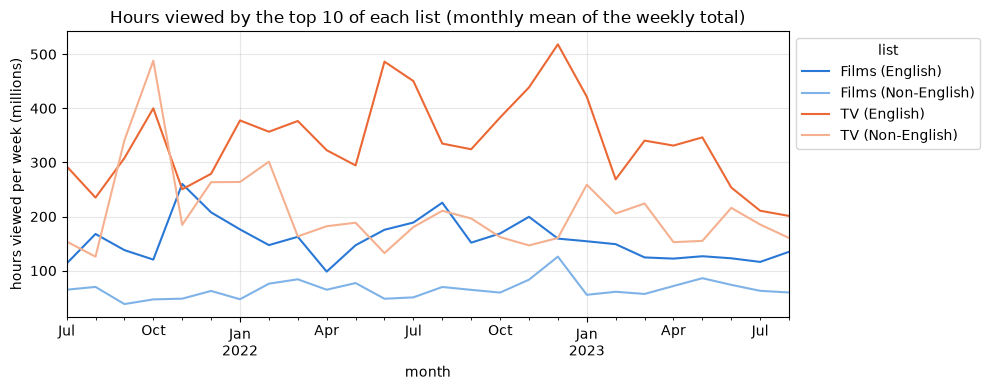

In [15]:
global_top_10["month"] = global_top_10["week"].dt.to_period("M").dt.to_timestamp() # add a column with the month of each week, to be able to group by month later

weekly_hours = global_top_10.groupby(["week", "category"])["weekly_hours_viewed"].sum().reset_index()  # get the total hours of each list each week

weekly_hours["month"] = weekly_hours["week"].dt.to_period("M").dt.to_timestamp()  # first day of the month of each week, to group weeks by month

monthly_hours = weekly_hours.pivot_table(values="weekly_hours_viewed", index="month", columns="category", aggfunc="mean")  # one row per month, one column per list with mean weekly hours

monthly_hours_millions = monthly_hours / 1_000_000  # hours in millions, easier to read on the axis
list_colors = [CATEGORY_COLORS[c] for c in monthly_hours_millions.columns]  # assign the same colour for each list like in the other plots

monthly_hours_millions.plot(color=list_colors, figsize=(10, 4))

plt.title("Hours viewed by the top 10 of each list (monthly mean of the weekly total)")
plt.xlabel("month")
plt.ylabel("hours viewed per week (millions)")
plt.legend(title="list", bbox_to_anchor=(1, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The English TV top 10 collects the most hours almost every month, with peaks when big seasons come out. Non-English TV passes it only in September and October 2021.

What I notice:

- In the combined top 10, TV takes most of the places. Part of this comes from the measure itself: hours favour long content, which is probably why Netflix moved to views.
- The mix moves from month to month with big releases, but TV stays on top. The hours of English TV are lower in 2023 than at the end of 2022; with only two years, I cannot tell if this is a trend or a period with fewer big releases.
- TV also stays longer in the top 10 (3.1 weeks), so whether a title is a film or a show, and in which language, should help the model.

## 4. Which countries watch the same things?

The global top 10 does not say *where* a title is watched. One of the guiding questions of the workspace asks about regional preferences: do some countries watch the same things?

To answer it, I group together the countries whose top 10 lists look alike, which I call **taste groups**. This part is a side study: it describes Netflix audiences around the world, and the models in Part 2 do not use it.

I use all the weeks of the data, from 2021 to 2023.

### 4.1 How similar are two countries?

Each week, a country has 20 titles in its lists (10 films and 10 TV). 

To compare two countries in a given week, I count the titles they have in common and divide by the number of different titles in their two lists together. 

This is called the **Jaccard similarity**: 1 means identical lists, 0 means nothing in common. I then average it over all the weeks.

I store each weekly list as a Python `set`, because sets directly give the titles in common (intersection `&`) and all the titles together (union `|`)

In [16]:
weekly_sets = (
    countries_top_10
    .groupby(["country_name", "week"])["key"] # makes one group for each country in each week, containing the keys of its 20 titles
    .apply(set) # get the set of title-seasons in the top 10 of each country and week
    .to_dict() # convert to a dictionary with (country, week) as key and set of title-seasons as value
    )  # build {(country, week): set of keys} 

country_names = sorted(countries_top_10["country_name"].unique())
all_weeks = sorted(countries_top_10["week"].unique())
print("Countries:", len(country_names))
print("Weeks:", len(all_weeks))

Countries: 94
Weeks: 113


In [17]:
similarity = pd.DataFrame(1.0, index=country_names, columns=country_names)  # set an empty DataFrame with 1.0 on the diagonal and 0.0 elsewhere, to store the similarity between countries

for i, country_a in enumerate(country_names): # fill the similarity matrix by comparing each country with all the other countries
    for country_b in country_names[i + 1:]: # run through the countries that come after country_a in the list, to avoid duplicate pairs and self-comparison
        overlaps = []
        for week in all_weeks:
            if (country_a, week) in weekly_sets and (country_b, week) in weekly_sets:  # check that both countries have a list that week
                set_a = weekly_sets[(country_a, week)]
                set_b = weekly_sets[(country_b, week)]

                overlaps.append(len(set_a & set_b) / len(set_a | set_b))  # Jaccard similarity of the week
                
        similarity.loc[country_a, country_b] = np.mean(overlaps)
        similarity.loc[country_b, country_a] = np.mean(overlaps)  # the matrix is symmetric

similarity.iloc[:8, :8].round(2)

,Argentina,Australia,Austria,Bahamas,Bahrain,Bangladesh,Belgium,Bolivia
Argentina,1.00,0.22,0.29,0.38,0.26,0.17,0.31,0.48
Australia,0.22,1.00,0.31,0.27,0.28,0.19,0.34,0.17
Austria,0.29,0.31,1.00,0.33,0.31,0.20,0.45,0.21
Bahamas,0.38,0.27,0.33,1.00,0.28,0.17,0.34,0.28
Bahrain,0.26,0.28,0.31,0.28,1.00,0.33,0.34,0.23
Bangladesh,0.17,0.19,0.20,0.17,0.33,1.00,0.21,0.19
Belgium,0.31,0.34,0.45,0.34,0.34,0.21,1.00,0.23
Bolivia,0.48,0.17,0.21,0.28,0.23,0.19,0.23,1.00


In [18]:
pairs = similarity.where(np.triu(np.ones(similarity.shape, dtype=bool), k=1)).stack()  # keep each pair once (upper triangle with no diagonal)

print("Most similar pairs:")
print(pairs.sort_values(ascending=False).head(5).round(2))
print("\nLeast similar pairs:")
print(pairs.sort_values().head(5).round(2))

Most similar pairs:
Guadeloupe   Martinique              0.90
Honduras     Nicaragua               0.83
Qatar        United Arab Emirates    0.83
Austria      Germany                 0.83
El Salvador  Honduras                0.82
dtype: float64

Least similar pairs:
Ireland  Japan             0.06
Japan    United Kingdom    0.06
         United States     0.06
Canada   Japan             0.07
Ireland  South Korea       0.07
dtype: float64


In [19]:
mean_similarity = (similarity.sum() - 1) / (len(country_names) - 1)  # mean similarity with the other countries (removing itself)
mean_similarity.sort_values(ascending=True).head(5).round(3)

Japan          0.095
South Korea    0.113
Taiwan         0.165
Vietnam        0.177
Thailand       0.180
dtype: float64

What I can notice here:

- The most similar pairs are neighbours that share a language or a culture: 
  - Guadeloupe and Martinique (0.90), 
  - Honduras and Nicaragua (0.83), 
  - Qatar and the United Arab Emirates (0.83), 
  - Austria and Germany (0.83) etc.
  
- The least similar pairs all put Japan or South Korea against English-speaking countries: 
  - Japan and Ireland share only 6% of their titles on average

- Japan has the lowest mean similarity with the other countries (0.095), then South Korea (0.113). Their top 10 lists are the most different from the rest of the world.

### 4.2 Building the groups with hierarchical clustering

Hierarchical clustering starts with every country on its own, then keeps merging the two closest groups until only one is left. 

The **dendrogram** draws these merges as a tree: the lower two countries join, the more similar they are.

- I use `1 - similarity` as the distance, so that similar countries stay close.
- `linkage` usually takes the features and computes the distances itself. Here I already have the distances, so I pass them with the `squareform` technique, which turns the table into the flat list of pairs that `linkage` expects.
- With **average** linkage, the distance between two groups is the average distance between their countries.

In [20]:
distance = 1 - similarity

mergings = linkage(squareform(distance.values, checks=False), method="average")  # average-linkage hierarchy on the distances

**How many groups?** To choose where to cut the tree, I use the elbow idea from k-means clustering. 

For hierarchical clustering, the equivalent of the k-means inertia is the **height of the merges**: 
- each row of `mergings` is one merge
- its third column is the distance at which the two groups join 
- The last row is the merge from 2 groups to 1, the row before it from 3 groups to 2, and so on.

If the next merge is high, it would join countries that are very different, so it is worth keeping them apart. When the curve flattens, extra groups only split countries that are already close.

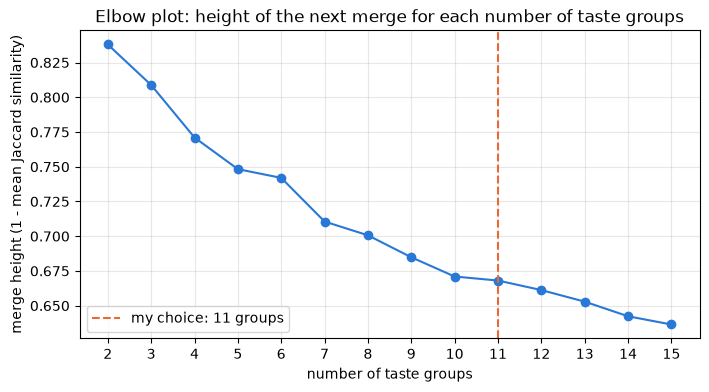

In [21]:
n_groups_options = list(range(2, 16))

merge_heights = []
for n_groups in n_groups_options:
    row = -(n_groups - 1)  # with n groups, the next merge is the (n - 1)th row from the end
    merge_heights.append(mergings[row, 2])  # column 2 = height of that merge

plt.figure(figsize=(8, 4))
plt.plot(n_groups_options, merge_heights, "-o", color=BLUE)
plt.axvline(N_TASTE_GROUPS, color=ORANGE, linestyle="--", label=f"my choice: {N_TASTE_GROUPS} groups")
plt.title("Elbow plot: height of the next merge for each number of taste groups")
plt.xlabel("number of taste groups")
plt.ylabel("merge height (1 - mean Jaccard similarity)")
plt.xticks(n_groups_options)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

The curve falls quickly until about 9 groups, then almost flattens from 10 groups on: the elbow is around 10 or 11 groups. I keep **11 taste groups** (`N_TASTE_GROUPS`): going from 10 to 11 separates France, its overseas territories and the African countries of the data from the rest of Europe, and their lists are quite different from it. 

With 7 groups or less, the curve would still be falling rapidly, so very different countries would end up in the same group.

This choice is not perfect: the elbow is not a sharp point, and the largest group still mixes countries that are not very alike. But the groups are easy to read and match real regions and languages, which is what I need to describe where Netflix audiences watch the same things.

In [22]:
# the dendrogram needs a height to colour the groups, so I convert "11 groups" into a height
height_last_kept = mergings[-N_TASTE_GROUPS, 2]  # last merge I keep: 12 groups -> 11
height_next = mergings[-(N_TASTE_GROUPS - 1), 2]  # next merge, which I do not want: 11 groups -> 10
cut_height = (height_last_kept + height_next) / 2  # any height between the two leaves exactly 11 groups, I take the middle

print("Cut height:", round(cut_height, 3))
print("Mean similarity at the cut:", round(1 - cut_height, 3))

Cut height: 0.665
Mean similarity at the cut: 0.335


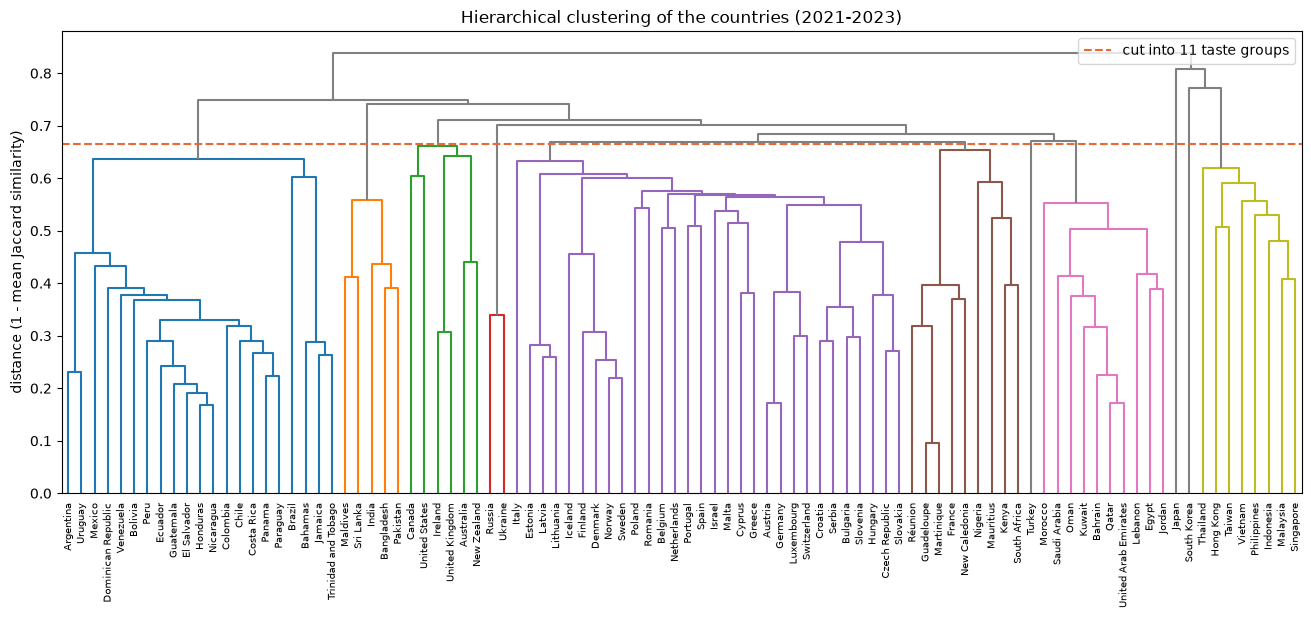

In [23]:
set_link_color_palette(["C0", "C1", "C2", "C3", "C4", "C5", "C6", "C8", "C9"])  # default colours without grey (C7), which is kept for the links merging above the cut

plt.figure(figsize=(16, 6))
dendrogram(mergings, 
           labels=distance.index.tolist(), # write country names on the x-axis
           leaf_rotation=90,
           leaf_font_size=7,
           color_threshold=cut_height, # color the links below the cut with one colour per group
           above_threshold_color="grey")  # color the links above the cut with grey

plt.axhline(cut_height, color=ORANGE, linestyle="--", label=f"cut into {N_TASTE_GROUPS} taste groups")
plt.title("Hierarchical clustering of the countries (2021-2023)")
plt.ylabel("distance (1 - mean Jaccard similarity)")
plt.legend()
plt.show()

The orange dashed line is where I cut the tree, at a height of 0.665, so a mean similarity of about 0.335. 

Each country has 20 titles a week, so we can say roughly that: **two groups stay apart when their countries share on average fewer than about 10 of their 20 titles.** 

Below the line, each colour is one taste group. The grey links are merges above the cut, and here Turkey, Japan and South Korea stay alone.

We can see here that :
- Latin America (blue, on the left) merges at the lowest distances: its countries watch very similar titles.
- Japan and South Korea only join the others near the top of the tree: they stay apart from every group.
- Europe is the largest group and merges at higher distances: its countries are less alike than the Latin American ones. France, its overseas territories and the African countries form their own group, which would join Europe just above the cut.

### 4.3 Eleven taste groups

`fcluster` cuts the tree into groups. With `criterion="maxclust"`, I ask directly for 11 groups instead of choosing a height. I name each group after its region, using one of its countries to find it.

In [24]:
cluster_labels = pd.Series(fcluster(mergings, N_TASTE_GROUPS, criterion="maxclust"), index=distance.index)  # assign one cluster number per country

TASTE_GROUP_NAMES = {  # one country that identifies each taste group to assign the name of the taste group
    "Germany": "Europe",
    "France": "France & Africa",
    "United States": "English-speaking",
    "Russia": "Russia & Ukraine",
    "Saudi Arabia": "Middle East & North Africa",
    "Turkey": "Turkey",
    "Brazil": "Latin America & Caribbean",
    "India": "South Asia",
    "Thailand": "Southeast & East Asia",
    "Japan": "Japan",
    "South Korea": "South Korea",
}
names_by_label = {cluster_labels[country]: name for country, name in TASTE_GROUP_NAMES.items()}  # combine the cluster number with selected taste group name
country_taste_group = cluster_labels.map(names_by_label)

for group_name in country_taste_group.value_counts().index:  # sort from the largest taste group to the smallest and print the list of countries in each taste group
    members = country_taste_group[country_taste_group == group_name].index.tolist()
    print(f"{group_name} ({len(members)}): {', '.join(members)}\n")

Europe (30): Austria, Belgium, Bulgaria, Croatia, Cyprus, Czech Republic, Denmark, Estonia, Finland, Germany, Greece, Hungary, Iceland, Israel, Italy, Latvia, Lithuania, Luxembourg, Malta, Netherlands, Norway, Poland, Portugal, Romania, Serbia, Slovakia, Slovenia, Spain, Sweden, Switzerland

Latin America & Caribbean (21): Argentina, Bahamas, Bolivia, Brazil, Chile, Colombia, Costa Rica, Dominican Republic, Ecuador, El Salvador, Guatemala, Honduras, Jamaica, Mexico, Nicaragua, Panama, Paraguay, Peru, Trinidad and Tobago, Uruguay, Venezuela

Middle East & North Africa (10): Bahrain, Egypt, Jordan, Kuwait, Lebanon, Morocco, Oman, Qatar, Saudi Arabia, United Arab Emirates

France & Africa (9): France, Guadeloupe, Kenya, Martinique, Mauritius, New Caledonia, Nigeria, Réunion, South Africa

Southeast & East Asia (8): Hong Kong, Indonesia, Malaysia, Philippines, Singapore, Taiwan, Thailand, Vietnam

English-speaking (6): Australia, Canada, Ireland, New Zealand, United Kingdom, United States


The eleven taste groups follow geography and language:

- **Europe** (30 countries), with Israel,
- **Latin America & Caribbean** (21, with Brazil even though it speaks Portuguese, and Jamaica, the Bahamas, and Trinidad and Tobago),
- **Middle East & North Africa** (10): the Arab countries of the data,
- **France & Africa** (9): France and its overseas territories, with Nigeria, Kenya, South Africa and Mauritius,
- **Southeast & East Asia** (8), from Hong Kong and Taiwan to Indonesia,
- **English-speaking** (6): United States, United Kingdom, Canada, Ireland, Australia and New Zealand,
- **South Asia** (5): India, Pakistan, Bangladesh, Sri Lanka and the Maldives,
- **Russia & Ukraine** (2). Russia only has data until February 2022, when Netflix left the country,
- **Japan**, **South Korea** and **Turkey**, each on its own.

In [25]:
TASTE_GROUP_COLORS = {  # one fixed colour per taste group
    "Europe": "#2a78d6",
    "France & Africa": "#9467bd",
    "English-speaking": "#7fb3e8",
    "Russia & Ukraine": "#17a2b8",
    "Middle East & North Africa": "#a0662d",
    "Turkey": "#d62728",
    "Latin America & Caribbean": "#1baf7a",
    "Southeast & East Asia": "#eda100",
    "South Asia": "#eb6834",
    "Japan": "#e87ba4",
    "South Korea": "#8c4fd6",
}

group_map = pd.DataFrame({"country": country_taste_group.index, "taste_group": country_taste_group.values}) # create a DataFrame with one row per country and its taste group, to use for the map

fig = px.choropleth(group_map, 
                    locations="country", 
                    locationmode="country names", 
                    color="taste_group",
                    color_discrete_map=TASTE_GROUP_COLORS, 
                    category_orders={"taste_group": list(TASTE_GROUP_COLORS)},
                    title="Netflix taste groups (2021-2023)")

fig.update_geos(projection_type="natural earth", projection_rotation_lon=0, showframe=False)  # world map centred on longitude 0
fig.update_layout(legend_title_text="taste group", margin={"l": 0, "r": 0, "t": 40, "b": 0}) # set the legend title and remove the empty white margins around the map
fig.show()

How to read the map:

- Each colored group represent the taste groups created earlier
- Some countries are too small to see: Guadeloupe, Martinique, Réunion and the Maldives.
- Grey countries are not in the data.

On the map, we can see that the taste groups follow geography, rare exceptions are:

- North America, United Kingdom, Ireland and Australia form the **English-speaking** group, far from each other but with the same tastes
- Asia splits into four groups: South Asia, Southeast Asia, Japan and South Korea.
- France is not with the rest of Europe. Its closest countries are its overseas territories, probably because they share the French catalogue, and through them it joins African countries such as Nigeria, Kenya and South Africa. This group is still close to Europe: the two would merge just above the cut.

# Part 2: Prediction

In Part 1, I explored the data. Now I use it to answer the question of the notebook: from its first week, can I predict whether a title will stay 4 weeks or more in the global top 10?

## 5. Describe each title by its first week

Until now, I explored the data as it comes in the files. To train a model and answer my question: **can the first week tell if a title will stay?**.

I need a different table: one row per title, with only the information available at the end of its first week (rank, hours viewed, countries...), and the answer to predict.

The raw files cannot be used directly, for three reasons:

1. **A title appears many times.** `global_top_10` has one row per title and per week, so a title that stays 8 weeks has 8 rows, and a title that leaves after 1 week has only 1. The model would see the long-runners many more times than the others.
2. **The later weeks give the answer away.** A row from week 5 shows `cumulative_weeks_in_top_10 = 5`, which already says that the title stayed. The team only has the first week when it decides, so the model must only see the first week too.
3. **The country information is in another file.** `countries_top_10` has one row per country, per title and per week. I need to sum it up into a few numbers per title, such as the number of countries where it is in the top 10.

So I build the table in two steps:

- **5.1** keeps the first week of each title and adds the answer: did it stay 4 weeks or more?
- **5.2** adds what the country lists say about that first week.

### 5.1 First week and outcome

A supervised learning model learns from examples: for each title, it needs **what it could see** at the moment of the prediction, and **what really happened** afterwards. By comparing the two on many past titles, it learns which first weeks lead to long runs.

So for each title I need two things:

- **What it could see: the first week only.** The prediction is made right after the debut, so I keep the debut row of each title (its rank and hours viewed) and nothing from the following weeks. 
  
- **What really happened: did the title stay 4 weeks or more?** I bring back `total_weeks`, the length of the whole run from 3.1, and turn it into the answer `stays_4_weeks` (1 = stayed 4+ weeks, 0 = left before).

The result, `debuts`, has one row per title-season.

In [26]:
debuts = global_top_10.sort_values("week").groupby("key").first()  # keep the first row of each key is its debut week, with its rank and hours viewed
debuts["total_weeks"] = title_runs["total_weeks"]  # final length of the weekly run (from section 3.1)
debuts["stays_4_weeks"] = (debuts["total_weeks"] >= TARGET_WEEKS).astype(int)  # our initial target: 1 if the title stays 4 weeks or more
print("Title-seasons:", len(debuts))

Title-seasons: 1606


This gives 1,606 rows, one per title-season. But some titles cannot be used, because I cannot see how their run starts or ends:

- **Already running when the data starts.** Netflix's week counter starts with this data: in the first week, all 40 titles show `cumulative_weeks_in_top_10 = 1`, even titles that came out months before (*The Mitchells vs. The Machines* came out in April 2021). So for the titles of the first week, I cannot see their real debut, and I set them aside.
- **Less than 4 weeks of data after the debut.** A title that debuts in the last 3 weeks cannot reach 4 weeks before the data stops, so I cannot know its answer. I set these titles aside. A title with at least 4 weeks of data is fine, even if it is still in the top 10 at the end: either it has already reached 4 weeks, or it left before.

In [27]:
first_week = global_top_10["week"].min()  # 2021-07-04, the first week of the data
already_running = debuts["week"] == first_week  # first seen in the first week: the real debut may be earlier
recent_debut = debuts["week"] > last_week - pd.Timedelta(weeks=TARGET_WEEKS - 1)  # less than 4 weeks of data, debut week included

print("Already running at the start:", already_running.sum()) # print the number of titles that are already running at the start
print("Debut in the last 3 weeks:", (recent_debut & ~already_running).sum()) # print the number of titles that debuted in the last 3 weeks of data

titles = debuts[~already_running & ~recent_debut].copy()  # the modelling table

print("\nTitles for the model:", len(titles))
print("Share staying 4+ weeks:", round(titles["stays_4_weeks"].mean(), 3))

Already running at the start: 40
Debut in the last 3 weeks: 43

Titles for the model: 1523
Share staying 4+ weeks: 0.23


- The 40 titles of the first week are set aside, because their real debut may be earlier.
- 43 titles start in the last 3 weeks and are set aside.
- That leaves **1,523 titles** in `titles`, and **23.0%** of them stay 4 weeks or more, about 1 title in 4.

### 5.2 What is known after week 1

For each title, the model gets five pieces of information, all about its debut week.

**Already in the debut row** (from the global list), I only need to prepare them:
- `debut_rank`: the global rank in the first week (1 is the best rank)
- `log_debut_hours`: the hours viewed in the first week, on a log scale. Hours go from about 1 million to 340 million, and the log keeps the biggest hits from crushing all the other values.
- `category`: film or TV, English or not. It becomes 0/1 dummy columns, with English films as the reference.

**To compute from the country lists** of the same week:
- `n_countries`: in how many countries the title is in the top 10
- `mean_country_rank`: its average rank over the 94 countries.
  - In the countries where the title is not in the top 10, it has no rank. I give it rank 11, meaning "just below the top 10".
  - Without this, a title ranked #1 in only 2 countries would get a better average (1.0) than a worldwide hit ranked #3 in 90 countries (3.0).
  - With it, a title only gets a good average if it ranks well in many countries.


**Step 1: find each title in the country lists of its debut week.** The country file has every week of every title, but the model may only use the debut week. So I merge it with the key and debut week of each title: the merge keeps only the rows where both match.

In [28]:
debut_weeks = titles[["week"]].reset_index()  # one row per title with its key and its debut week

debut_countries = countries_top_10.merge(debut_weeks, on=["key", "week"])  # keep only the country rows of each title in its debut week

debut_countries[["key", "week", "country_name", "weekly_rank"]].head()  # one row = one title in one country's top 10

,key,week,country_name,weekly_rank
0,Shark Bait|,2023-08-06,Argentina,2
1,Soulcatcher|,2023-08-06,Argentina,4
2,Zom 100: Bucket List of the Dead|,2023-08-06,Argentina,9
3,No Ritmo da Fé|,2023-08-06,Argentina,10
4,Heartstopper|Heartstopper: Season 2,2023-08-06,Argentina,2


**Step 2: count the countries.** For each title, I count the different countries in these rows. A title that is in no country list has no rows at all, so pandas gives it an empty value (NaN) that I replace it with 0.

In [29]:
titles["n_countries"] = debut_countries.groupby("key")["country_name"].nunique()  # number of countries where the title is in the top 10
titles["n_countries"] = titles["n_countries"].fillna(0)  # titles in no country list

**Step 3: the mean rank over the 94 countries.** For each title, I add up its ranks in the countries where it is in the top 10, add 11 for each country where it is absent, and divide by 94. A title in no country list is absent everywhere, so its mean rank is 11.

In [30]:
n_all_countries = countries_top_10["country_name"].nunique()  # 94 countries

rank_sum = debut_countries.groupby("key")["weekly_rank"].sum()  # sum of the ranks in the countries where the title is in the top 10
n_absent = n_all_countries - titles["n_countries"]  # number of countries where the title is not in the top 10

titles["mean_country_rank"] = (rank_sum + ABSENT_RANK * n_absent) / n_all_countries  # absent countries count as rank 11
titles["mean_country_rank"] = titles["mean_country_rank"].fillna(ABSENT_RANK)  # titles absent everywhere are given the absent rank of 11, to avoid NaN values in the column

**Step 4: write a summary of all the columns.** 

In [31]:
titles["debut_rank"] = titles["weekly_rank"]  # keep the same column but with a clearer name
titles["log_debut_hours"] = np.log(titles["weekly_hours_viewed"]) # compute the log of the debut hours, to reduce the effect of outliers

titles[["category", "debut_rank", "log_debut_hours", "n_countries", "mean_country_rank", "stays_4_weeks"]].describe().round(2) # summary statistics of the features and target variable

,debut_rank,log_debut_hours,n_countries,mean_country_rank,stays_4_weeks
count,1523.00,1523.00,1523.00,1523.00,1523.00
mean,5.61,16.21,28.16,9.13,0.23
std,2.91,0.94,28.37,2.38,0.42
min,1.00,13.93,0.00,1.00,0.00
25%,3.00,15.66,6.00,8.73,0.00
50%,6.00,16.20,18.00,10.09,0.00
75%,8.00,16.78,43.50,10.76,0.00
max,10.00,19.65,94.00,11.00,1.00


- In its first week, a title is in the top 10 of 28 countries on average (median 18).
- 24 titles are in no country list at all. Those I looked at are at the bottom of the global list (ranks 8 to 10), so they are probably watched a little everywhere without being in the top 10 of any country. They get 0 countries and a mean country rank of 11.
- `log_debut_hours` goes from 13.9 to 19.7, which would correspond to about 1 million to 340 million hours.

In [32]:
titles[["debut_rank", "log_debut_hours", "n_countries", "mean_country_rank", "stays_4_weeks"]].corr().round(2) # correlation matrix of the features and target variable

,debut_rank,log_debut_hours,n_countries,mean_country_rank,stays_4_weeks
debut_rank,1.00,-0.62,-0.69,0.67,-0.42
log_debut_hours,-0.62,1.00,0.74,-0.72,0.45
n_countries,-0.69,0.74,1.00,-0.95,0.44
mean_country_rank,0.67,-0.72,-0.95,1.00,-0.46
stays_4_weeks,-0.42,0.45,0.44,-0.46,1.00


- Every feature is linked to the outcome with a similar strength (correlations between 0.40 and 0.46 in absolute value). 
  - `mean_country_rank` (-0.46) and `log_debut_hours` (0.45) are the strongest correlated values.
- The features are also strongly linked to each other. `n_countries` and `mean_country_rank` have a correlation of -0.95, so we could consider that they carry almost the same information.

## 6. Predict which titles will stay

### 6.1 Learn from the past, test on the future

The Netflix content team will use the model on new titles, so I test it the same way. The models learn from the titles that started in 2021–2022, and are tested on the titles that started in 2023. A random split would mix the two periods and make the test easier than real life.

In [33]:
numeric_features = ["debut_rank", "log_debut_hours", "n_countries", "mean_country_rank"] # selectonly numeric features for the model, the categorical feature are encoded with dummies
category_dummies = pd.get_dummies(titles["category"], drop_first=True, dtype=int)  # one 0/1 column per list with English films as the reference

X = pd.concat([titles[numeric_features], category_dummies], axis=1) 
y = titles["stays_4_weeks"]

# Split the data into training and test sets based on the debut week 
is_train = titles["week"].dt.year <= 2022  # 2021-2022 debuts for training, 2023 for the test
X_train, X_test = X[is_train], X[~is_train]
y_train, y_test = y[is_train], y[~is_train]

print("Train set:", X_train.shape, "with a share staying of:", round(y_train.mean(), 3))
print("Test set:", X_test.shape, "with a share staying of:", round(y_test.mean(), 3))

Train set: (1086, 7) with a share staying of: 0.238
Test set: (437, 7) with a share staying of: 0.211


- The train set has 1,086 titles and the test set 437. 
- 23.8% of the train titles stay 4+ weeks against 21.1% of the test titles. 
- As seen in 3.2, the global rank of the last test weeks is based on views, while the train set is always ranked by hours.

### 6.2 How far does one signal go?

To score the models I use the **ROC AUC**. 

In plain words; take one title that stayed and one that did not, the AUC would be the chance that the model gives the higher score to the one that stayed. 0.5 is a coin flip and 1 is perfect. It does not need a threshold, which helps here because only about 1 title in 4 stays.

Before building models, I check how far **a single signal** gets: the debut rank on its own, and the number of countries alone. A better rank is a smaller number, so I use minus the rank as the score.

In [34]:
baseline_rank_auc = roc_auc_score(y_test, -X_test["debut_rank"])  # a rank of 1 must get the highest score
baseline_countries_auc = roc_auc_score(y_test, X_test["n_countries"])

print("Test AUC, debut rank alone:", round(baseline_rank_auc, 3))
print("Test AUC, number of countries alone:", round(baseline_countries_auc, 3))

Test AUC, debut rank alone: 0.817
Test AUC, number of countries alone: 0.826


The debut rank alone already gives an AUC of 0.817, and the number of countries 0.826. A model is only useful if it does clearly better than about 0.82.

### 6.3 Two models

I compare two models that learn in very different ways, on the same features:

- a **logistic regression**: it gives each feature a weight and adds them up, so it can only draw straight-line boundaries. 
- a **gradient boosting** classifier: it builds small trees one after the other, each one fixing the errors of the previous ones, so it can catch curves and interactions between features.

If gradient boosting does clearly better, the link between the first week and the outcome is more complex than a straight line. If not, the simpler model is enough.

The logistic regression needs features on the same scale, so a `StandardScaler` comes first. 

I also pick the best model on its 5-fold cross-validation AUC on the training titles, and the 2023 test set will only give the final score.

In [35]:
logreg_steps = [("scaler", StandardScaler()),  # step 1: put all features on the same scale
                ("logreg", LogisticRegression())]  # step 2: the model

models = {
    "Logistic regression": Pipeline(logreg_steps),
    "Gradient boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
results = []
test_probs = {}  # list of predicted probabilities on the test set, for the plots

for model_name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=kf, scoring="roc_auc")  # 5 AUC values, one per fold
    model.fit(X_train, y_train)  # refit on the whole train set
    test_probs[model_name] = model.predict_proba(X_test)[:, 1]  # probability of staying 4+ weeks

    results.append({
        "Model": model_name,
        "CV AUC": cv_auc.mean(),
        "CV AUC std": cv_auc.std(),
        "Test AUC": roc_auc_score(y_test, test_probs[model_name]),
    })

results_table = pd.DataFrame(results).set_index("Model")
results_table.loc["Baseline: debut rank"] = [np.nan, np.nan, baseline_rank_auc] # add the baseline AUC for debut rank to the results table
results_table.loc["Baseline: number of countries"] = [np.nan, np.nan, baseline_countries_auc] # add the baseline AUC for number of countries to the results table
results_table.round(3)

,CV AUC,CV AUC std,Test AUC
Model,,,
Logistic regression,0.812,0.035,0.870
Gradient boosting,0.810,0.024,0.889
Baseline: debut rank,NaN,NaN,0.817
Baseline: number of countries,NaN,NaN,0.826


- Both models beat the two single signals on the test set: by about 0.04 for the logistic regression and 0.06 for gradient boosting.
- The logistic regression has a slightly better CV AUC (0.812 against 0.810), so it becomes `best_model`. Gradient boosting is better on the 2023 test (0.889 against 0.870).
- The two scores disagree, and in both cases the gap between the models (0.002 in CV, 0.019 on the test) is smaller than the variation between the CV folds (standard deviation 0.024 to 0.035). With 1,086 titles to learn from, I cannot say that one model is really better: here, the more flexible model does not clearly beat the straight-line one. 

I will keep the rule I set before seeing the results: the best CV AUC wins.
- The test AUCs (0.87 to 0.89) are higher than the CV AUCs (0.81): the 2023 titles were easier to rank than the 2021–2022 ones. I do not know why, so I need to read the test AUC of a single year with care.

In [36]:
best_name = results_table["CV AUC"].idxmax()  # the model with the best cross-validation AUC
best_model = models[best_name]
best_test_auc = results_table.loc[best_name, "Test AUC"]

print("Best model:", best_name)
print("Test AUC:", round(best_test_auc, 3))

Best model: Logistic regression
Test AUC: 0.87


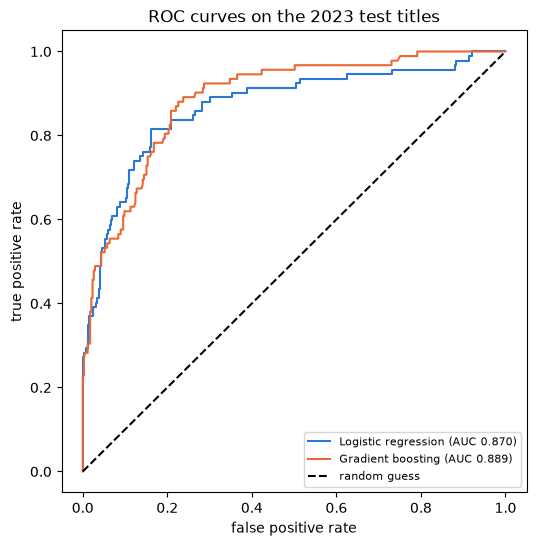

In [37]:
plt.figure(figsize=(6, 6))

for model_name, color in zip(models, [BLUE, ORANGE]):
    fpr, tpr, thresholds = roc_curve(y_test, test_probs[model_name])
    
    plt.plot(fpr, tpr, color=color, label=f"{model_name} (AUC {results_table.loc[model_name, 'Test AUC']:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="random guess")
plt.title("ROC curves on the 2023 test titles")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.legend(loc="lower right", fontsize=8)
plt.show()

The two curves are close and cross several times: no model is better at every threshold, and both are far above the random guess.

### 6.4 From a probability to a decision

The model gives each title a probability of staying 4 or more weeks, but the Netflix content team would need a yes or no: push the title or not. 

The cut (also called the threshold) turns the probability into that answer: a title with a probability at or above the cut gets a "yes", a title below it gets a "no". By default the cut is at $p = 0.5$, so a title is pushed when the model finds it more likely to stay than to leave. 

Moving the cut changes the kind of mistakes we collect. A higher cut pushes fewer titles, so fewer false alarms but more missed hits, and a lower cut does the opposite.

Missing a future long-runner (a false negative) means no support for a title that would have stayed longer, while a false alarm (a false positive) costs a marketing push for nothing. A missed hit still succeeds on its own (maybe a bit less than with the push), while a false alarm is money actually spent for nothing. 

So I prefer to avoid false alarms: 
- I keep the default cut at 0.5, 
- I also try a higher cut at 0.7, which pushes fewer titles but is right more often, and do not overspend.

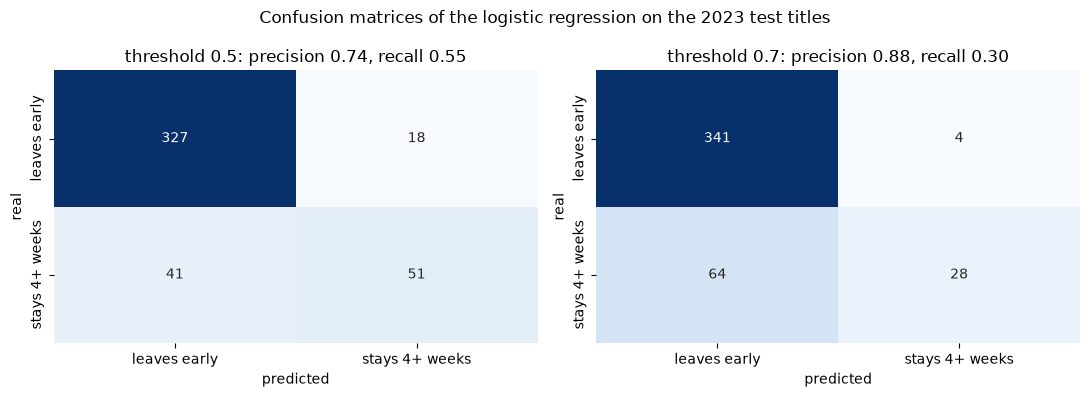

In [38]:
best_test_probs = test_probs[best_name]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, threshold in zip(axes, [0.5, 0.7]):
    y_pred = (best_test_probs >= threshold).astype(int)  # 1 = predicted to stay 4+ weeks

    matrix = confusion_matrix(y_test, y_pred)
    sns.heatmap(matrix, 
                annot=True, 
                fmt="d", 
                cmap="Blues", 
                cbar=False, 
                ax=ax,
                xticklabels=["leaves early", "stays 4+ weeks"], 
                yticklabels=["leaves early", "stays 4+ weeks"])
    
    true_negatives, false_positives, false_negatives, true_positives = matrix.ravel() # unpack the confusion matrix into its four components

    precision = true_positives / (true_positives + false_positives)  # share of pushed titles that really stay

    recall = true_positives / (true_positives + false_negatives)  # share of long-runners that are pushed 

    ax.set_title(f"threshold {threshold}: precision {precision:.2f}, recall {recall:.2f}")
    ax.set_xlabel("predicted")
    ax.set_ylabel("real")

plt.suptitle(f"Confusion matrices of the {best_name.lower()} on the 2023 test titles")
plt.tight_layout()
plt.show()

- At **0.5**, the model pushes 69 titles and 51 of them really stay (precision 0.74), but it misses 41 of the 92 long-runners (recall 0.55).
- At **0.7**, it pushes only 32 titles and 28 of them really stay (precision 0.88), but it misses 64 of the 92 long-runners (recall 0.30).

The right threshold depends on how much a push costs, which I do not know. With 0.5, about 3 pushes in 4 go to a title that really stays. With 0.7, almost 9 in 10 do, but the team only pushes the most obvious hits and leaves most long-runners without support.

## 7. What the predictions rely on

A good score is not enough: I also want to know which information each model uses to decide, to check that its choices make sense and to turn them into simple advice.

### 7.1 Logistic regression coefficients

Each bar shows how strongly one feature pushes the prediction. A bar to the right means that a higher value makes the title more likely to stay 4 or more weeks in the top 10, and a bar to the left means less likely. 

Before training, the pipeline put all features on the same scale (StandardScaler), so the bars can be compared: the longer the bar, the stronger the effect.

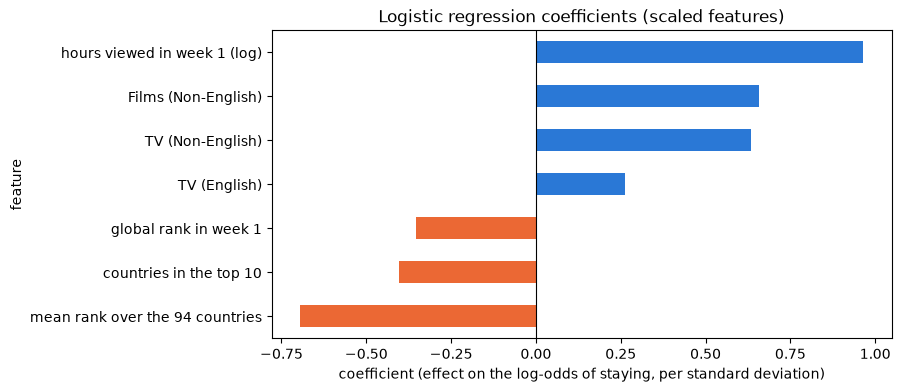

In [39]:
FEATURE_LABELS = {  # readable names for the charts
    "debut_rank": "global rank in week 1",
    "log_debut_hours": "hours viewed in week 1 (log)",
    "n_countries": "countries in the top 10",
    "mean_country_rank": "mean rank over the 94 countries",
}

logreg = models["Logistic regression"].named_steps["logreg"]  # get the model out of the pipeline created earlier, to then access its coefficients
coefficients = pd.Series(logreg.coef_[0], index=X.columns).rename(FEATURE_LABELS)  # create a series with one coefficient per feature with readable names

coefficients.sort_values().plot(
    kind="barh", 
    color=[ORANGE if c < 0 else BLUE for c in coefficients.sort_values()], 
    figsize=(8, 4)
    )

plt.title("Logistic regression coefficients (scaled features)")
plt.xlabel("coefficient (effect on the log-odds of staying, per standard deviation)")
plt.ylabel("feature")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

- The hours viewed in week 1 have the largest positive effect, more hours means a better chance of staying.
- The three lists other than English films are positive meaning that with the same first week, non-English films, English TV and non-English TV stay longer than English films.
- The global rank is negative as expected, a bigger rank number (a lower place) lowers the chance.
- The number of countries and the mean country rank are both negative, which looks contradictory, since more countries should help. This comes from their correlation of -0.95, the model shares the same information between the two, so their signs cannot be read one by one.

### 7.2 Gradient boosting feature importances

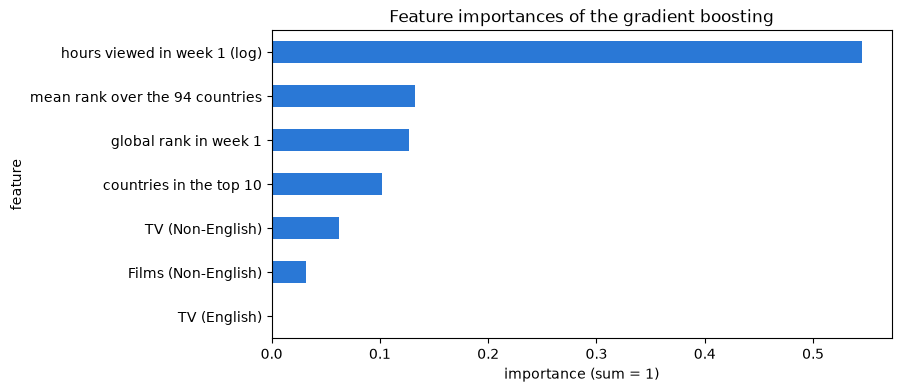

In [40]:
gradient_boosting = models["Gradient boosting"]
importances = pd.Series(gradient_boosting.feature_importances_, index=X.columns).rename(FEATURE_LABELS)

importances.sort_values().plot(
    kind="barh", 
    color=BLUE, 
    figsize=(8, 4)
    )

plt.title("Feature importances of the gradient boosting")
plt.xlabel("importance (sum = 1)")
plt.ylabel("feature")
plt.show()

Gradient boosting relies mostly on the hours viewed in week 1 (0.55). The country signals and the global rank come next (0.10 to 0.13), and the type of title matters little. Both models agree that the hours of the first week are the most useful signal.

In [41]:
summary = results_table[["CV AUC", "Test AUC"]].copy()
summary["Test AUC gain over debut rank"] = summary["Test AUC"] - baseline_rank_auc
summary.sort_values("Test AUC", ascending=False).round(3)

,CV AUC,Test AUC,Test AUC gain over debut rank
Model,,,
Gradient boosting,0.810,0.889,0.072
Logistic regression,0.812,0.870,0.053
Baseline: number of countries,NaN,0.826,0.009
Baseline: debut rank,NaN,0.817,0.000


**Summary:** The question was whether a title's first week in the global top 10 tells if it will stay there 4 weeks or more. I described 1,523 titles by their first week (rank, hours viewed, number of countries and mean rank across the countries), trained two models on the 2021–2022 titles and tested them on the 2023 titles. The models rank the 2023 titles with an AUC of 0.87 to 0.89, against 0.82 for the debut rank alone. So yes, the first week still says somethign about the success of the title.

**What the exploration shows**

- Most titles leave the top 10 quickly, and TV seasons stay longer than films.
- The 94 countries form eleven taste groups that follow geography and language.
  - Tastes sometimes follow language more than distance. The English-speaking countries form one group across four continents. France first connects with its overseas territories and the African countries rather than with the rest of Europe.
  - Japan and South Korea watch the most different titles, and Turkey also stays on its own. A global hit says little about what does well there.
  - Inside a group, countries share a large part of their weekly top 10. So a group, not a single country, is a natural unit for a regional launch or a regional marketing push.

**What the models show**

- The hours viewed in week 1 are the strongest signal, followed by the rank and the number of countries.
- The type of title matters, with the same first week, non-English titles and TV shows stay longer than English films.
- The logistic regression has the best CV AUC and becomes `best_model` (test AUC `best_test_auc` = 0.870). Gradient boosting is better on the 2023 test (0.889), but the difference between the 2 are smaller than the variation between CV folds. Here, the more flexible model does not clearly beat the simple one, which is also the easiest to explain.

**Advice for the content team**

1. Score each new title after its first week and keep the big marketing push for the high probabilities. With a cut at 0.5, about 3 pushed titles in 4 really stay. With 0.7, almost 9 in 10 do, but most long-runners get no push.
2. Do not judge non-English titles and TV shows against English films, the same success in the first week is a better sign for them that they will stay longer.
3. Look at the hours viewed first. A title that collects many hours in its first week is the best candidate for a long run.
4. Use the model as a routine, score the new titles now, and see a few weeks later which ones really stayed. This checks that it keeps working on new titles.

**Data issues and how I handled them**

The data is not perfectly clean, and some of its problems could bias the results. This is how I dealt with each one even though it is not perfect

| Data issue | How I handled it |
| --- | --- |
| Netflix ranks by hours until June 2023, then by views (3.2) | The training titles are all ranked by hours. For the test titles after the switch, I kept Netflix's new rank because a quick check showed that recomputing it by hours barely changes the results. Which titles enter the top 10 after June 2023 still depends on views. |
| Netflix's week counter starts with already running data (5.1) | The 40 titles of the first week may have debuted earlier, so I set them aside. |
| The most recent titles have no known outcome yet (5.1) | Only titles with at least 4 weeks of data are used, so the 43 newest ones are also set aside. |
| Hours favour series over films (3.3) | The models never compare films and series, a title only has to stay in its own list. |
| We are missing some crucial data that could help the models predict | The data has no genre and no viewer rating. It cannot be fixed with this dataset because Netflix do not provide this information. A next step would be to join IMDb, using the genres and only the ratings known at the end of the first week. |

**Limits**

- The data only has titles that made the global top 10, so it says nothing about titles that never chart.
- The ranking technique changes in June 2023, so the last test weeks are ranked by runtime and views and the training titles by hours.
- The results come from one small split in time. The test AUC is higher than the CV AUC, and the gaps between the models are small.
- The number of taste groups is a judgement call, the elbow is around 10 or 11 groups, but it's not a sharp point.
- The 4-week threshold is my choice from the original workbook. I did not test other.
- A title only needs 4 weeks of data to know its answer, but a title can leave the top 10 and come back later. A 2023 title with 2 or 3 weeks could come back after the data stops and pass 4 weeks, so a few test answers may be wrong.
- Gradient boosting uses its default settings: I did not tune it.